<a href="https://colab.research.google.com/github/Haiyaa00/ABSA-Capstone-Project/blob/main/Hotel_v2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')
%cd /content/drive/MyDrive/absa-2018/experiments


Mounted at /content/drive
/content/drive/MyDrive/absa-2018/experiments


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ds4v/absa-vlsp-2018/blob/main/experiments/Hotel-v1.ipynb)

In [2]:
!pip install -q emoji
!pip install -q vncorenlp
!pip install -q datasets
!pip install -q accelerate
!pip install -q transformers

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [3]:
!pip install "transformers<5.0.0"


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 141.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 30.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 141.8 MB/s  0:00:00
  Attempting uninstall: huggingface-hub
    Found existing installation: huggingface_hub 1.33.0
    Uninstalling huggingface_hub-1.33.0:
      Successfully uninstalled huggingface_hub-1.33.0
  Attempting uninstall: tokenizers
    Found existing installation: tokenizers 0.23.3
    Uninstalling tokenizers-0.23.3:
      Successfully uninstalled tokenizers-0.23.3
  Attempting uninstall: transformers
    Found existing installation: transformers 5.20.2
    Uninstalling transformers-5.20.2:
      Successfully uninstalled transformers-5.20.2
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [transformers]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency co

In [4]:
import os
import sys
from google.colab import drive

# 1. Mount Google Drive nếu chưa mount
if not os.path.exists('/content/drive/MyDrive'):
    drive.mount('/content/drive')

# 2. Danh sách các vị trí thường đặt trên Drive để kiểm tra nhanh
candidate_paths = [
    '/content/drive/MyDrive/absa-2018',
    '/content/drive/MyDrive/HAU Capstone Project/absa-2018',
    '/content/drive/MyDrive/absa-vlsp-2018',
    '/content/drive/MyDrive/Colab Notebooks/absa-2018',
    '/content/absa-vlsp-2018',
    '/content/absa-2018'
]

found_project_dir = None
for p in candidate_paths:
    if os.path.exists(os.path.join(p, 'processors', 'vlsp2018_processor.py')):
        found_project_dir = p
        break

# Nếu chưa tìm thấy ở các đường dẫn trên, quét tìm tự động trên MyDrive
if not found_project_dir:
    print("🔍 Đang tìm kiếm vị trí thư mục dự án trên Google Drive...")
    for root, dirs, files in os.walk('/content/drive/MyDrive'):
        if 'vlsp2018_processor.py' in files and 'processors' in root:
            found_project_dir = os.path.abspath(os.path.join(root, '..'))
            break

if found_project_dir:
    print(f"✅ Đã tìm thấy thư mục dự án tại: {found_project_dir}")

    # Thêm thư mục gốc vào đầu danh sách tìm kiếm module của Python
    if found_project_dir not in sys.path:
        sys.path.insert(0, found_project_dir)

    # Chuyển thư mục làm việc vào thư mục experiments
    exp_dir = os.path.join(found_project_dir, 'experiments')
    if os.path.exists(exp_dir):
        os.chdir(exp_dir)
    else:
        os.chdir(found_project_dir)

    print(f"✅ Thư mục làm việc hiện tại: {os.getcwd()}")
    print("🚀 Đường dẫn đã được cấu hình chuẩn xác! Bạn hãy chạy tiếp các cell bên dưới.")
else:
    print("❌ Không tìm thấy thư mục chứa code trên Google Drive!")
    print("👉 Hãy kiểm tra xem bạn đã upload thư mục absa-2018 lên Google Drive chưa nhé.")


✅ Đã tìm thấy thư mục dự án tại: /content/drive/MyDrive/absa-2018
✅ Thư mục làm việc hiện tại: /content/drive/MyDrive/absa-2018/experiments
🚀 Đường dẫn đã được cấu hình chuẩn xác! Bạn hãy chạy tiếp các cell bên dưới.


In [ ]:
# !git clone https://github.com/ds4v/absa-vlsp-2018.git
# %cd ./absa-vlsp-2018/experiments
# !mkdir predictions
# !ls

In [5]:
import os
os.environ['TF_USE_LEGACY_KERAS'] = '1'

import sys
import numpy as np
import pandas as pd
import tensorflow as tf
sys.path.append('..')
tf.__version__

'2.21.0'

In [6]:
if tf.config.list_physical_devices('GPU'):
    physical_devices = tf.config.list_physical_devices('GPU')
    tf.config.experimental.set_memory_growth(physical_devices[0], True)
    print('Using GPU:', tf.test.gpu_device_name())
    !nvcc -V
else: raise ValueError('Running on CPU is not recommended.')

Using GPU: /device:GPU:0
nvcc: NVIDIA (R) Cuda compiler driver
Copyright (c) 2005-2025 NVIDIA Corporation
Built on Wed_Aug_20_01:58:59_PM_PDT_2025
Cuda compilation tools, release 13.0, V13.0.88
Build cuda_13.0.r13.0/compiler.36424714_0


# Constants Setup and Load the Data

In [7]:
TRAIN_PATH = r'../datasets/vlsp2018_hotel/1-VLSP2018-SA-Hotel-train.csv'
VAL_PATH = r'../datasets/vlsp2018_hotel/2-VLSP2018-SA-Hotel-dev.csv'
TEST_PATH = r'../datasets/vlsp2018_hotel/3-VLSP2018-SA-Hotel-test.csv'
PRETRAINED_MODEL = 'vinai/phobert-base'
MODEL_NAME = 'Hotel-v2' # Multitask model on Hotel domain
MAX_LENGTH = 256
BATCH_SIZE = 25
EPOCHS = 20

In [8]:
from processors.vlsp2018_processor import VLSP2018Loader
raw_datasets = VLSP2018Loader.load(TRAIN_PATH, VAL_PATH, TEST_PATH)
raw_datasets

Generating train split: 0 examples [00:00, ? examples/s]

Generating val split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['Review', 'FACILITIES#CLEANLINESS', 'FACILITIES#COMFORT', 'FACILITIES#DESIGN&FEATURES', 'FACILITIES#GENERAL', 'FACILITIES#MISCELLANEOUS', 'FACILITIES#PRICES', 'FACILITIES#QUALITY', 'FOOD&DRINKS#MISCELLANEOUS', 'FOOD&DRINKS#PRICES', 'FOOD&DRINKS#QUALITY', 'FOOD&DRINKS#STYLE&OPTIONS', 'HOTEL#CLEANLINESS', 'HOTEL#COMFORT', 'HOTEL#DESIGN&FEATURES', 'HOTEL#GENERAL', 'HOTEL#MISCELLANEOUS', 'HOTEL#PRICES', 'HOTEL#QUALITY', 'LOCATION#GENERAL', 'ROOMS#CLEANLINESS', 'ROOMS#COMFORT', 'ROOMS#DESIGN&FEATURES', 'ROOMS#GENERAL', 'ROOMS#MISCELLANEOUS', 'ROOMS#PRICES', 'ROOMS#QUALITY', 'ROOM_AMENITIES#CLEANLINESS', 'ROOM_AMENITIES#COMFORT', 'ROOM_AMENITIES#DESIGN&FEATURES', 'ROOM_AMENITIES#GENERAL', 'ROOM_AMENITIES#MISCELLANEOUS', 'ROOM_AMENITIES#PRICES', 'ROOM_AMENITIES#QUALITY', 'SERVICE#GENERAL'],
        num_rows: 3000
    })
    val: Dataset({
        features: ['Review', 'FACILITIES#CLEANLINESS', 'FACILITIES#COMFORT', 'FACILITIES#DESIGN&FEATUR

# Preprocess and Tokenize the Data

In [9]:
from processors.vietnamese_processor import VietnameseTextPreprocessor

# You should be carefull when using single word replacement for acronyms, because it can cause misinterpretation.
# For example, 'giá': ['price', 'gia'] can replace the word 'gia' in 'gia đình', making it become 'giá đình'.
vn_preprocessor = VietnameseTextPreprocessor(vncorenlp_dir='../processors/VnCoreNLP', extra_teencodes={
    'khách sạn': ['ks'], 'nhà hàng': ['nhahang'], 'nhân viên': ['nv'],
    'cửa hàng': ['store', 'sop', 'shopE', 'shop'],
    'sản phẩm': ['sp', 'product'], 'hàng': ['hàg'],
    'giao hàng': ['ship', 'delivery', 'síp'], 'đặt hàng': ['order'],
    'chuẩn chính hãng': ['authentic', 'aut', 'auth'], 'hạn sử dụng': ['date', 'hsd'],
    'điện thoại': ['dt'],  'facebook': ['fb', 'face'],
    'nhắn tin': ['nt', 'ib'], 'trả lời': ['tl', 'trl', 'rep'],
    'feedback': ['fback', 'fedback'], 'sử dụng': ['sd'], 'xài': ['sài'],
}, max_correction_length=MAX_LENGTH)

VnCoreNLP word segmenter is loaded successfully.


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/961 [00:00<?, ?B/s]

`torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors:   0%|          | 0.00/1.58G [00:00<?, ?B/s]

...

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

dict.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/279 [00:00<?, ?B/s]

Device set to use cuda:0


bmd1905/vietnamese-correction-v2 is loaded successfully.


In [10]:
from transformers import AutoTokenizer
tokenizer = AutoTokenizer.from_pretrained(PRETRAINED_MODEL)
tokens = tokenizer.encode('Tôi là sinh_viên trường đại_học Công_nghệ thông_tin .')
print('Encode:', tokens, '\nDecode:', tokenizer.decode(tokens))
tokenizer.model_input_names

config.json:   0%|          | 0.00/557 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

bpe.codes: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Encode: [0, 218, 8, 649, 212, 956, 2413, 195, 5, 2] 
Decode: <s> Tôi là sinh_viên trường đại_học Công_nghệ thông_tin . </s>


['input_ids', 'token_type_ids', 'attention_mask']

In [ ]:
# preprocessed_datasets = VLSP2018Loader.preprocess_and_tokenize(raw_datasets, vn_preprocessor, tokenizer, BATCH_SIZE * 2, MAX_LENGTH)
# preprocessed_datasets.save_to_disk('../datasets/preprocessed_hotel')
# display(preprocessed_datasets)
# pd.DataFrame({
#     'raw_datasets': raw_datasets['train']['Review'][1480:1490],
#     'encoded_input_ids': preprocessed_datasets['train']['input_ids'][1480:1490],
#     'decoded_input_ids': [tokenizer.decode(preprocessed_datasets['train'][i]['input_ids']) for i in range(1480, 1490)]
# })

[INFO] Preprocessing and tokenizing text data...


Map:   0%|          | 0/3000 [00:00<?, ? examples/s]

You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Map:   0%|          | 0/600 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/3000 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/2000 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/600 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['FACILITIES#CLEANLINESS', 'FACILITIES#COMFORT', 'FACILITIES#DESIGN&FEATURES', 'FACILITIES#GENERAL', 'FACILITIES#MISCELLANEOUS', 'FACILITIES#PRICES', 'FACILITIES#QUALITY', 'FOOD&DRINKS#MISCELLANEOUS', 'FOOD&DRINKS#PRICES', 'FOOD&DRINKS#QUALITY', 'FOOD&DRINKS#STYLE&OPTIONS', 'HOTEL#CLEANLINESS', 'HOTEL#COMFORT', 'HOTEL#DESIGN&FEATURES', 'HOTEL#GENERAL', 'HOTEL#MISCELLANEOUS', 'HOTEL#PRICES', 'HOTEL#QUALITY', 'LOCATION#GENERAL', 'ROOMS#CLEANLINESS', 'ROOMS#COMFORT', 'ROOMS#DESIGN&FEATURES', 'ROOMS#GENERAL', 'ROOMS#MISCELLANEOUS', 'ROOMS#PRICES', 'ROOMS#QUALITY', 'ROOM_AMENITIES#CLEANLINESS', 'ROOM_AMENITIES#COMFORT', 'ROOM_AMENITIES#DESIGN&FEATURES', 'ROOM_AMENITIES#GENERAL', 'ROOM_AMENITIES#MISCELLANEOUS', 'ROOM_AMENITIES#PRICES', 'ROOM_AMENITIES#QUALITY', 'SERVICE#GENERAL', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 3000
    })
    val: Dataset({
        features: ['FACILITIES#CLEANLINESS', 'FACILITIES#COMFOR

,raw_datasets,encoded_input_ids,decoded_input_ids
0,Nhan viên phục vụ chu đáo Tuy chuyến du lịch c...,"[0, 650, 533, 5655, 2442, 550, 388, 7, 70, 66,...",<s> nhân_viên phục_vụ chu_đáo tuy chuyến du_lị...
1,"Bãi biển đẹp - Phục vụ tốt- Thức ăn ngon, giá ...","[0, 1162, 262, 258, 533, 167, 1849, 1325, 3401...",<s> bãi biển đẹp phục_vụ tốt thức_ăn ngon giá_...
2,Phòng nằm gần biển đẹp Phục vụ phòng t...,"[0, 292, 339, 124, 262, 258, 533, 292, 167, 58...",<s> phòng nằm gần biển đẹp phục_vụ phòng tốt d...
3,Nhân viên chuyên nghiệp tuyệt Khách sạn nằm ở ...,"[0, 650, 1564, 3518, 1299, 339, 25, 442, 9756,...",<s> nhân_viên chuyên_nghiệp tuyệt khách_sạn nằ...
4,Gia đình mình đã có 4 ngày 3 đêm lưu trú tại C...,"[0, 161, 68, 14, 10, 163, 43, 107, 396, 6567, ...",<s> gia_đình mình đã có 4 ngày 3 đêm lưu_trú t...
5,"Tôi ở đây 3 ngày 2 đêm, khách sạn không đúng v...","[0, 70, 25, 97, 107, 43, 76, 396, 1299, 17, 28...",<s> tôi ở đây 3 ngày 2 đêm khách_sạn không đún...
6,"Resort đẹp, Nhân viên phục vụ tận tình. Mình r...","[0, 9823, 258, 650, 533, 9787, 68, 59, 2273, 2...",<s> resort đẹp nhân_viên phục_vụ tận_tình mình...
7,Đây là lần đầu tiên chúng tôi đến Phú Quốc. Nh...,"[0, 97, 8, 101, 191, 283, 30, 56407, 3705, 595...",<s> đây là lần đầu_tiên chúng_tôi đến phú_quốc...
8,Tuy chuyến du lịch của tôi chỉ kéo dài có 3 ng...,"[0, 2442, 550, 388, 7, 70, 66, 832, 10, 107, 4...",<s> tuy chuyến du_lịch của tôi chỉ kéo_dài có ...
9,Bình Minh Resort Cable Car Vũng Tàu (KDL Cáp T...,"[0, 14872, 9823, 1395, 22820, 26283, 44439, 59...",<s> bình_minh resort cable car vũng_tàu khu cá...


In [11]:
from datasets import load_from_disk
preprocessed_datasets = load_from_disk('../datasets/preprocessed_hotel')
preprocessed_datasets

DatasetDict({
    train: Dataset({
        features: ['FACILITIES#CLEANLINESS', 'FACILITIES#COMFORT', 'FACILITIES#DESIGN&FEATURES', 'FACILITIES#GENERAL', 'FACILITIES#MISCELLANEOUS', 'FACILITIES#PRICES', 'FACILITIES#QUALITY', 'FOOD&DRINKS#MISCELLANEOUS', 'FOOD&DRINKS#PRICES', 'FOOD&DRINKS#QUALITY', 'FOOD&DRINKS#STYLE&OPTIONS', 'HOTEL#CLEANLINESS', 'HOTEL#COMFORT', 'HOTEL#DESIGN&FEATURES', 'HOTEL#GENERAL', 'HOTEL#MISCELLANEOUS', 'HOTEL#PRICES', 'HOTEL#QUALITY', 'LOCATION#GENERAL', 'ROOMS#CLEANLINESS', 'ROOMS#COMFORT', 'ROOMS#DESIGN&FEATURES', 'ROOMS#GENERAL', 'ROOMS#MISCELLANEOUS', 'ROOMS#PRICES', 'ROOMS#QUALITY', 'ROOM_AMENITIES#CLEANLINESS', 'ROOM_AMENITIES#COMFORT', 'ROOM_AMENITIES#DESIGN&FEATURES', 'ROOM_AMENITIES#GENERAL', 'ROOM_AMENITIES#MISCELLANEOUS', 'ROOM_AMENITIES#PRICES', 'ROOM_AMENITIES#QUALITY', 'SERVICE#GENERAL', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 3000
    })
    val: Dataset({
        features: ['FACILITIES#CLEANLINESS', 'FACILITIES#COMFOR

# Prepare for TensorFlow Training

In [12]:
# Tensorflow only accepts targeted column names prefixed with 'output_'
MULTI_BRANCH_NAMES = {old_name: f'output_{i + 1}' for i, old_name in enumerate(raw_datasets['train'].column_names[1:])}
preprocessed_datasets = preprocessed_datasets.rename_columns(MULTI_BRANCH_NAMES)
steps_per_epoch = len(preprocessed_datasets['train']) // BATCH_SIZE
total_steps = EPOCHS * steps_per_epoch
print(MULTI_BRANCH_NAMES)

{'FACILITIES#CLEANLINESS': 'output_1', 'FACILITIES#COMFORT': 'output_2', 'FACILITIES#DESIGN&FEATURES': 'output_3', 'FACILITIES#GENERAL': 'output_4', 'FACILITIES#MISCELLANEOUS': 'output_5', 'FACILITIES#PRICES': 'output_6', 'FACILITIES#QUALITY': 'output_7', 'FOOD&DRINKS#MISCELLANEOUS': 'output_8', 'FOOD&DRINKS#PRICES': 'output_9', 'FOOD&DRINKS#QUALITY': 'output_10', 'FOOD&DRINKS#STYLE&OPTIONS': 'output_11', 'HOTEL#CLEANLINESS': 'output_12', 'HOTEL#COMFORT': 'output_13', 'HOTEL#DESIGN&FEATURES': 'output_14', 'HOTEL#GENERAL': 'output_15', 'HOTEL#MISCELLANEOUS': 'output_16', 'HOTEL#PRICES': 'output_17', 'HOTEL#QUALITY': 'output_18', 'LOCATION#GENERAL': 'output_19', 'ROOMS#CLEANLINESS': 'output_20', 'ROOMS#COMFORT': 'output_21', 'ROOMS#DESIGN&FEATURES': 'output_22', 'ROOMS#GENERAL': 'output_23', 'ROOMS#MISCELLANEOUS': 'output_24', 'ROOMS#PRICES': 'output_25', 'ROOMS#QUALITY': 'output_26', 'ROOM_AMENITIES#CLEANLINESS': 'output_27', 'ROOM_AMENITIES#COMFORT': 'output_28', 'ROOM_AMENITIES#DESIGN

In [13]:
train_tf_dataset = preprocessed_datasets['train'].to_tf_dataset(
    columns=tokenizer.model_input_names, label_cols=list(MULTI_BRANCH_NAMES.values()),
    batch_size=BATCH_SIZE, shuffle=True, num_workers=8
)
val_tf_dataset = preprocessed_datasets['val'].to_tf_dataset(
    columns=tokenizer.model_input_names, label_cols=list(MULTI_BRANCH_NAMES.values()),
    batch_size=BATCH_SIZE, shuffle=False, num_workers=8
)
test_tf_dataset = preprocessed_datasets['test'].to_tf_dataset(
    columns=tokenizer.model_input_names, label_cols=list(MULTI_BRANCH_NAMES.values()),
    batch_size=BATCH_SIZE, shuffle=False, num_workers=8
)

In [14]:
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.optimizers.schedules import CosineDecay
from tensorflow.keras.callbacks import EarlyStopping

optimizer = Adam(learning_rate=CosineDecay(
    initial_learning_rate = 1e-4,
    warmup_target = 2e-4,
    warmup_steps = int(total_steps * 0.15), # 15% of total_steps
    decay_steps = int(total_steps * 0.3), # Next 30% of total_steps
    alpha = 0.1, # Minimum lr for decay as a fraction of initial_learning_rate
))

early_stop_callback = EarlyStopping(
    monitor = 'val_loss',
    patience = 3, # Stop if no improvement after 3 epochs
    restore_best_weights = True, # You may obtain HIGHER metrics on the test set with longer training time if you set this to False
    # Because after some experiments, I found that even with higher val_loss, it still results in better metric reports on the test set.
    # This maybe because the training set and the test set have more similarities than the validation data.
    # But I think this is not fair, as we already have prior knowledge about the test set and we modified our training based on the performance on this set.
    # In real-world, we should only modify our training based on the performance on the validation data
    verbose = 1
)

# Fine-tuning with TensorFlow

tf_model.h5:   0%|          | 0.00/740M [00:00<?, ?B/s]

TensorFlow and JAX classes are deprecated and will be removed in Transformers v5. We recommend migrating to PyTorch classes or pinning your version of Transformers.
Some layers from the model checkpoint at vinai/phobert-base were not used when initializing TFRobertaModel: ['lm_head']
- This IS expected if you are initializing TFRobertaModel from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing TFRobertaModel from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).
All the layers of TFRobertaModel were initialized from the model checkpoint at vinai/phobert-base.
If your task is similar to the task the model of the checkpoint was trained on, you can already use TFRobertaModel for predictions without further traini

Epoch 1/20


120/120 [==============================] - 320s 2s/step - loss: 14.4358 - output_1_loss: 0.2937 - output_2_loss: 0.2462 - output_3_loss: 0.6082 - output_4_loss: 0.3351 - output_5_loss: 0.1140 - output_6_loss: 0.1450 - output_7_loss: 0.3378 - output_8_loss: 0.0778 - output_9_loss: 0.2520 - output_10_loss: 0.7002 - output_11_loss: 0.6358 - output_12_loss: 0.4436 - output_13_loss: 0.7879 - output_14_loss: 0.8012 - output_15_loss: 0.9075 - output_16_loss: 0.2191 - output_17_loss: 0.5553 - output_18_loss: 0.3826 - output_19_loss: 0.8773 - output_20_loss: 0.6706 - output_21_loss: 0.5302 - output_22_loss: 0.8377 - output_23_loss: 0.3886 - output_24_loss: 0.0656 - output_25_loss: 0.3201 - output_26_loss: 0.2956 - output_27_loss: 0.1848 - output_28_loss: 0.1992 - output_29_loss: 0.4621 - output_30_loss: 0.3505 - output_31_loss: 0.0448 - output_32_loss: 0.0490 - output_33_loss: 0.3509 - output_34_loss: 0.9658 - val_loss: 10.4193 - val_output_1_loss: 0.0715 - val_output_2_loss: 0.1715 - val_outpu

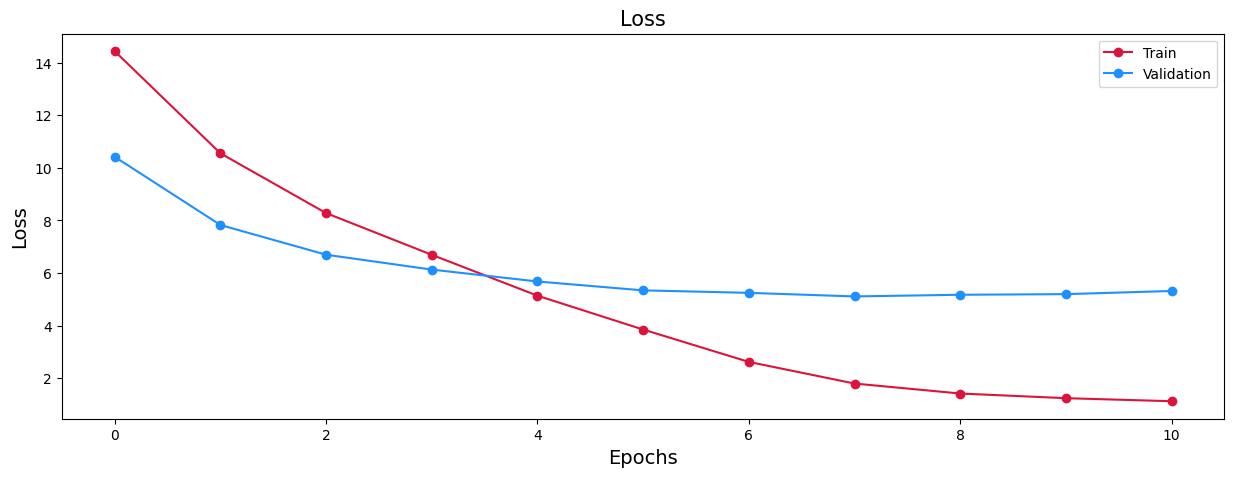

CPU times: user 19min 49s, sys: 3min 1s, total: 22min 51s
Wall time: 48min 8s


In [15]:
%%time
from acsa_model import VLSP2018MultiTask
from helper import plot_training_history
model = VLSP2018MultiTask(PRETRAINED_MODEL, MULTI_BRANCH_NAMES, optimizer, multi_branch=True, name=MODEL_NAME)

history = model.fit(
    train_tf_dataset,
    validation_data = val_tf_dataset,
    callbacks = [early_stop_callback],
    epochs = EPOCHS,
    verbose = 1
).history

model.save_weights(f'./weights/{MODEL_NAME}/{MODEL_NAME}', save_format='tf')
plot_training_history(history)

In [16]:
from google.colab import drive # Move weights to Drive for faster downloading
drive.mount('/content/GoogleDrive', force_remount=True)
!zip -r ./weights/{MODEL_NAME}.zip ./weights/{MODEL_NAME}
!mv ./weights/{MODEL_NAME}.zip /content/GoogleDrive/My\ Drive

Mounted at /content/GoogleDrive
	zip warning: name not matched: ./weights/Hotel-v2

zip error: Nothing to do! (try: zip -r ./weights/Hotel-v2.zip . -i ./weights/Hotel-v2)
mv: cannot stat './weights/Hotel-v2.zip': Transport endpoint is not connected


In [17]:
import os
import sys
from google.colab import drive

# 1. Thoát khỏi thư mục bị đứt kết nối về thư mục gốc an toàn
os.chdir('/content')

# 2. Kết nối lại Google Drive về thư mục chuẩn /content/drive
drive.mount('/content/drive', force_remount=True)

# 3. Tự động xác định lại vị trí dự án trên Drive
candidate_paths = [
    '/content/drive/MyDrive/absa-2018',
    '/content/drive/MyDrive/HAU Capstone Project/absa-2018',
    '/content/drive/MyDrive/absa-vlsp-2018',
    '/content/drive/MyDrive/Colab Notebooks/absa-2018'
]

project_dir = None
for p in candidate_paths:
    if os.path.exists(os.path.join(p, 'experiments')):
        project_dir = p
        break

if not project_dir:
    for root, dirs, files in os.walk('/content/drive/MyDrive'):
        if 'Hotel-v2.ipynb' in files:
            project_dir = os.path.abspath(os.path.join(root, '..'))
            break

print("📂 Thư mục dự án:", project_dir)

# 4. Kiểm tra file weights đã lưu trên Drive chưa
weights_dir = os.path.join(project_dir, 'experiments', 'weights', 'Hotel-v2')
if os.path.exists(weights_dir):
    print("✅ File trọng số của bạn đã nằm an toàn trên Google Drive:")
    print(os.listdir(weights_dir))

    # Chuyển thư mục làm việc về experiments để chạy tiếp các cell đánh giá
    os.chdir(os.path.join(project_dir, 'experiments'))

    # 5. Nén file zip ngay tại chỗ (để tải về máy tính nếu muốn)
    !zip -r ./weights/Hotel-v2.zip ./weights/Hotel-v2
    print("🎉 Đã tạo file ./weights/Hotel-v2.zip thành công!")
else:
    print("⚠️ Không tìm thấy thư mục weights, hãy kiểm tra lại đường dẫn.")


Mounted at /content/drive
📂 Thư mục dự án: /content/drive/MyDrive/absa-2018
✅ File trọng số của bạn đã nằm an toàn trên Google Drive:
['Hotel-v2.index', 'Hotel-v2.data-00000-of-00001', 'checkpoint']
updating: weights/Hotel-v2/ (stored 0%)
updating: weights/Hotel-v2/Hotel-v2.data-00000-of-00001 (deflated 32%)
updating: weights/Hotel-v2/Hotel-v2.index (deflated 80%)
updating: weights/Hotel-v2/checkpoint (deflated 37%)
🎉 Đã tạo file ./weights/Hotel-v2.zip thành công!


# Predict on the Test Data

In [19]:
from acsa_model import VLSP2018MultiTask
reloaded_model = VLSP2018MultiTask(PRETRAINED_MODEL, MULTI_BRANCH_NAMES, optimizer, multi_branch=True, name=MODEL_NAME)
reloaded_model.load_weights(f'./weights/{MODEL_NAME}/{MODEL_NAME}') # Reload the Model
reloaded_model.evaluate(val_tf_dataset, batch_size=BATCH_SIZE, verbose=1)

Some layers from the model checkpoint at vinai/phobert-base were not used when initializing TFRobertaModel: ['lm_head']
- This IS expected if you are initializing TFRobertaModel from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing TFRobertaModel from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).
All the layers of TFRobertaModel were initialized from the model checkpoint at vinai/phobert-base.
If your task is similar to the task the model of the checkpoint was trained on, you can already use TFRobertaModel for predictions without further training.


80/80 [==============================] - 78s 442ms/step - loss: 5.1099 - output_1_loss: 0.0342 - output_2_loss: 0.1332 - output_3_loss: 0.2694 - output_4_loss: 0.0942 - output_5_loss: 0.0226 - output_6_loss: 0.0615 - output_7_loss: 0.1067 - output_8_loss: 0.0319 - output_9_loss: 0.0673 - output_10_loss: 0.1244 - output_11_loss: 0.1692 - output_12_loss: 0.1043 - output_13_loss: 0.4432 - output_14_loss: 0.2700 - output_15_loss: 0.2589 - output_16_loss: 0.3024 - output_17_loss: 0.1119 - output_18_loss: 0.0547 - output_19_loss: 0.1281 - output_20_loss: 0.2056 - output_21_loss: 0.2499 - output_22_loss: 0.2643 - output_23_loss: 0.1279 - output_24_loss: 0.0221 - output_25_loss: 0.0718 - output_26_loss: 0.0260 - output_27_loss: 0.1375 - output_28_loss: 0.2551 - output_29_loss: 0.4027 - output_30_loss: 0.0845 - output_31_loss: 0.0138 - output_32_loss: 0.0286 - output_33_loss: 0.1950 - output_34_loss: 0.2370


[5.109936237335205,
 0.034208718687295914,
 0.13317261636257172,
 0.26944994926452637,
 0.09420269727706909,
 0.02257685735821724,
 0.06152520328760147,
 0.10669194906949997,
 0.03190532326698303,
 0.06727375835180283,
 0.12442516535520554,
 0.16920632123947144,
 0.10433633625507355,
 0.4432237446308136,
 0.26996996998786926,
 0.2588856518268585,
 0.30243349075317383,
 0.11191072314977646,
 0.054679565131664276,
 0.1280554234981537,
 0.20555788278579712,
 0.24987153708934784,
 0.26425570249557495,
 0.12794244289398193,
 0.0220707505941391,
 0.0718025490641594,
 0.026012586429715157,
 0.13749228417873383,
 0.2551076114177704,
 0.4027339220046997,
 0.08453049510717392,
 0.013848538510501385,
 0.0285834688693285,
 0.19499719142913818,
 0.2369956374168396]

In [20]:
y_pred = reloaded_model.acsa_predict(test_tf_dataset, BATCH_SIZE) # On test set
reloaded_model.evaluate(test_tf_dataset, batch_size=BATCH_SIZE, verbose=1)
print('Example:', raw_datasets['test'][0]['Review'])
reloaded_model.print_acsa_pred(y_pred[0])

24/24 [==============================] - 46s 485ms/step - loss: 6.1974 - output_1_loss: 0.0416 - output_2_loss: 0.1775 - output_3_loss: 0.2711 - output_4_loss: 0.0993 - output_5_loss: 0.0844 - output_6_loss: 0.0757 - output_7_loss: 0.2161 - output_8_loss: 0.0343 - output_9_loss: 0.0622 - output_10_loss: 0.1581 - output_11_loss: 0.1948 - output_12_loss: 0.1419 - output_13_loss: 0.3487 - output_14_loss: 0.1828 - output_15_loss: 0.2719 - output_16_loss: 0.5050 - output_17_loss: 0.1525 - output_18_loss: 0.0912 - output_19_loss: 0.1530 - output_20_loss: 0.2955 - output_21_loss: 0.2350 - output_22_loss: 0.4006 - output_23_loss: 0.2617 - output_24_loss: 0.0604 - output_25_loss: 0.1180 - output_26_loss: 0.0563 - output_27_loss: 0.1944 - output_28_loss: 0.2548 - output_29_loss: 0.4263 - output_30_loss: 0.0908 - output_31_loss: 0.0372 - output_32_loss: 0.0145 - output_33_loss: 0.2769 - output_34_loss: 0.2127
Example: Ga giường không sạch, nhân viên quên dọn phòng một ngày.
=> ROOMS#CLEANLI

In [21]:
from tensorflow.data import Dataset # On a random review by user
user_review = input('Enter your review: ')
cleaned_review = vn_preprocessor.process_batch([user_review], correct_errors=False)

tokenized_input = tokenizer(
    cleaned_review,
    max_length=MAX_LENGTH,
    padding='max_length',
    truncation=True
)

tf_inputs = Dataset.from_tensor_slices({
    x: [[tokenized_input[x][0]]] for x in tokenizer.model_input_names
})

random_pred = reloaded_model.acsa_predict(tf_inputs)
reloaded_model.print_acsa_pred(random_pred[0])

Enter your review: Lễ tân thân thiện, có thang máy, vị trí ks thuận tiện, view thành phố rất đẹp. Phòng sạch nhưng hơi nhỏ & thiếu bình đun siêu tốc. Sẽ quay lại & giới thiệu bạn bè
1/1 [==============================] - 2s 2s/step
=> HOTEL#DESIGN&FEATURES,positive
=> HOTEL#GENERAL,positive
=> LOCATION#GENERAL,positive
=> ROOMS#CLEANLINESS,positive
=> ROOMS#DESIGN&FEATURES,negative
=> ROOM_AMENITIES#DESIGN&FEATURES,negative
=> SERVICE#GENERAL,positive


# Scikit-learn Evaluation

In [22]:
from datasets import load_from_disk
preprocessed_datasets = load_from_disk('../datasets/preprocessed_hotel')
preprocessed_datasets

y_test = preprocessed_datasets['test'].remove_columns(tokenizer.model_input_names)
y_test = y_test.to_pandas().to_numpy()
y_test

array([[0, 0, 0, ..., 0, 0, 2],
       [0, 0, 0, ..., 0, 0, 1],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 1],
       [0, 0, 0, ..., 0, 0, 1],
       [0, 0, 0, ..., 0, 0, 0]])

In [23]:
import sys
import os

if '..' not in sys.path:
    sys.path.append('..')

from evaluators.sklearn_evaluator import VLSP2018SklearnEvaluator
sk_eval = VLSP2018SklearnEvaluator(y_test, y_pred, list(MULTI_BRANCH_NAMES))
# sk_eval.report(report_type='Aspect#Category,Polarity').round(3)
# sk_eval.report(report_type='Aspect#Category').round(3)
# sk_eval.report(report_type='Polarity').round(3)
# sk_eval.report(report_type='macro_avg').round(3)
sk_eval.report(report_type='all')

100%|██████████| 37/37 [00:00<00:00, 53941.34it/s]


ACSA Report (w/o "None" polarity) 
 Aspect#Category 
 Aspect#Category,Polarity 
 
 
 precision recall f1-score support precision recall f1-score support 
 
 
 
 FACILITIES#CLEANLINESS,positive 
 0.667 0.400 0.500 5.0 
 0.000 0.000 0.000 2.0 
 
 
 
 FACILITIES#CLEANLINESS,negative 
 
 1.000 0.333 0.500 3.0 
 
 
 
 FACILITIES#COMFORT,positive 
 1.000 0.000 0.000 26.0 
 1.000 0.000 0.000 20.0 
 
 
 
 FACILITIES#COMFORT,negative 
 
 1.000 0.000 0.000 6.0 
 
 
 
 FACILITIES#DESIGN&FEATURES,positive 
 0.711 0.492 0.582 65.0 
 0.650 0.342 0.448 38.0 
 
 
 
 FACILITIES#DESIGN&FEATURES,negative 
 
 0.560 0.636 0.596 22.0 
 
 
 
 FACILITIES#DESIGN&FEATURES,neutral 
 
 1.000 0.000 0.000 5.0 
 
 
 
 FACILITIES#GENERAL,positive 
 0.550 0.524 0.537 21.0 
 0.450 0.474 0.462 19.0 
 
 
 
 FACILITIES#GENERAL,negative 
 
 1.000 0.000 0.000 1.0 
 
 
 
 FACILITIES#GENERAL,neutral 
 
 1.000 0.000 0.000 1.0 
 
 
 
 FACILITIES#MISCELLANEOUS,positive 
 1.000 0.000 0.000 8.0 
 1.000 0.000 0.000 3.0 
 
 
 
 FACILITIES#MISCELLANEOUS,negative 
 
 1.000 0.000 0.000 5.0 
 
 
 
 FACILITIES#PRICES,positive 
 0.400 0.154 0.222 13.0 
 0.667 0.250 0.364 8.0 
 
 
 
 FACILITIES#PRICES,negative 
 
 0.000 0.000 0.000 3.0 
 
 
 
 FACILITIES#PRICES,neutral 
 
 1.000 0.000 0.000 2.0 
 
 
 
 FACILITIES#QUALITY,positive 
 0.857 0.588 0.698 51.0 
 1.000 0.292 0.452 24.0 
 
 
 
 FACILITIES#QUALITY,negative 
 
 0.679 0.760 0.717 25.0 
 
 
 
 FACILITIES#QUALITY,neutral 
 
 1.000 0.000 0.000 2.0 
 
 
 
 FOOD&DRINKS#MISCELLANEOUS,positive 
 1.000 0.000 0.000 3.0 
 1.000 0.000 0.000 1.0 
 
 
 
 FOOD&DRINKS#MISCELLANEOUS,negative 
 
 1.000 0.000 0.000 2.0 
 
 
 
 FOOD&DRINKS#PRICES,positive 
 0.200 0.111 0.143 9.0 
 1.000 0.167 0.286 6.0 
 
 
 
 FOOD&DRINKS#PRICES,negative 
 
 0.000 0.000 0.000 3.0 
 
 
 
 FOOD&DRINKS#QUALITY,positive 
 0.951 0.899 0.924 129.0 
 0.919 0.948 0.933 96.0 
 
 
 
 FOOD&DRINKS#QUALITY,negative 
 
 0.737 0.737 0.737 19.0 
 
 
 
 FOOD&DRINKS#QUALITY,neutral 
 
 1.000 0.286 0.444 14.0 
 
 
 
 FOOD&DRINKS#STYLE&OPTIONS,positive 
 0.947 0.863 0.903 124.0 
 0.902 0.860 0.881 43.0 
 
 
 
 FOOD&DRINKS#STYLE&OPTIONS,negative 
 
 0.903 0.867 0.884 75.0 
 
 
 
 FOOD&DRINKS#STYLE&OPTIONS,neutral 
 
 1.000 0.000 0.000 6.0 
 
 
 
 HOTEL#CLEANLINESS,positive 
 0.883 0.791 0.835 67.0 
 0.881 0.881 0.881 59.0 
 
 
 
 HOTEL#CLEANLINESS,negative 
 
 1.000 0.125 0.222 8.0 
 
 
 
 HOTEL#COMFORT,positive 
 0.688 0.702 0.695 94.0 
 0.729 0.775 0.752 80.0 
 
 
 
 HOTEL#COMFORT,negative 
 
 0.182 0.154 0.167 13.0 
 
 
 
 HOTEL#COMFORT,neutral 
 
 1.000 0.000 0.000 1.0 
 
 
 
 HOTEL#DESIGN&FEATURES,positive 
 0.785 0.859 0.820 85.0 
 0.779 0.905 0.838 74.0 
 
 
 
 HOTEL#DESIGN&FEATURES,negative 
 
 0.500 0.375 0.429 8.0 
 
 
 
 HOTEL#DESIGN&FEATURES,neutral 
 
 0.000 0.000 0.000 3.0 
 
 
 
 HOTEL#GENERAL,positive 
 0.871 0.848 0.859 151.0 
 0.859 0.859 0.859 135.0 
 
 
 
 HOTEL#GENERAL,negative 
 
 0.778 0.583 0.667 12.0 
 
 
 
 HOTEL#GENERAL,neutral 
 
 0.667 0.500 0.571 4.0 
 
 
 
 HOTEL#MISCELLANEOUS,positive 
 0.474 0.132 0.207 68.0 
 0.000 0.000 0.000 29.0 
 
 
 
 HOTEL#MISCELLANEOUS,negative 
 
 0.389 0.206 0.269 34.0 
 
 
 
 HOTEL#MISCELLANEOUS,neutral 
 
 1.000 0.000 0.000 5.0 
 
 
 
 HOTEL#PRICES,positive 
 0.819 0.831 0.825 71.0 
 0.846 0.873 0.859 63.0 
 
 
 
 HOTEL#PRICES,negative 
 
 0.143 0.167 0.154 6.0 
 
 
 
 HOTEL#PRICES,neutral 
 
 1.000 0.000 0.000 2.0 
 
 
 
 HOTEL#QUALITY,positive 
 0.778 0.538 0.636 13.0 
 0.600 0.429 0.500 7.0 
 
 
 
 HOTEL#QUALITY,negative 
 
 0.750 0.600 0.667 5.0 
 
 
 
 HOTEL#QUALITY,neutral 
 
 1.000 0.000 0.000 1.0 
 
 
 
 LOCATION#GENERAL,positive 
 0.973 0.968 0.971 221.0 
 0.959 0.984 0.971 190.0 
 
 
 
 LOCATION#GENERAL,negative 
 
 0.609 0.875 0.718 16.0 
 
 
 
 LOCATION#GENERAL,neutral 
 
 1.000 0.133 0.235 15.0 
 
 
 
 ROOMS#CLEANLINESS,positive 
 0.830 0.950 0.886 200.0 
 0.870 0.964 0.914 166.0 
 
 
 
 ROOMS#CLEANLINESS,negative 
 
 0.467 0.778 0.583 27.0 
 
 
 
 ROOMS#CLEANLINESS,neutral 
 
 1.000 0.000 0.000 7.0 
 
 
 


# VLSP Evaluation

In [24]:
from processors.vlsp2018_processor import VLSP2018Parser
VLSP2018Parser.vlsp_save_as(f'./predictions/{MODEL_NAME}.txt', raw_datasets['test']['Review'], y_pred, MULTI_BRANCH_NAMES)
!java ../evaluators/SAEvaluate.java {TEST_PATH.replace('.csv', '.txt')} ./predictions/{MODEL_NAME}.txt

600it [00:00, 2924.51it/s]


[0.002s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.002s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
Row mismatch:﻿#1 <-> #1
Evaluation Result >> File:./predictions/Hotel-v2.txt<> [../datasets/vlsp2018_hotel/3-VLSP2018-SA-Hotel-test.txt]
                    Gold count	46	416	200	93	221	57	198	67	68	144	32	124	10	65	85	51	13	71	151	29	94	21	68	59	8	26	129	3	13	9	5	4	3	1
                  ANSWER count	36	411	229	119	220	34	193	60	27	113	38	113	8	45	93	35	9	72	147	42	96	20	19	63	0	0	122	0	5	5	3	0	0	0

        Correct ANSWER: aspect	17	403	190	82	214	25	167	53	22	91	27	107	5	32	73	30	7	59	128	23	66	11	9	30	0	0	116	0	2	1	2	0	0	0
             Precision: aspect	0.4722	0.9805	0.8297	0.6891	0.9727	0.7353	0.8653	0.8833	0.8148	0.8053	0.7105	0.9469	0.6250	0.7111	0.7849	0.85